# **1. Perceptron Mistakes**


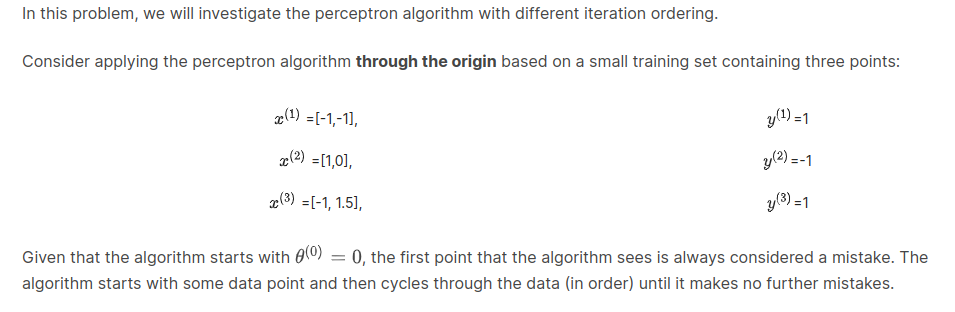

## **1 (a) Perceptron algo with different iteration order**

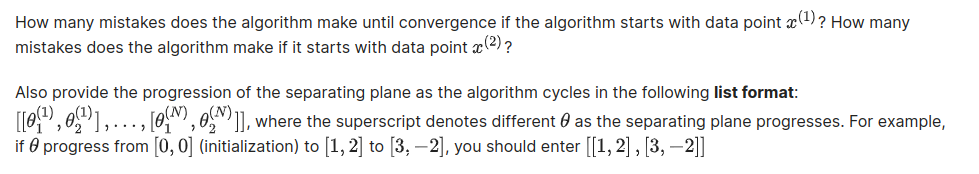

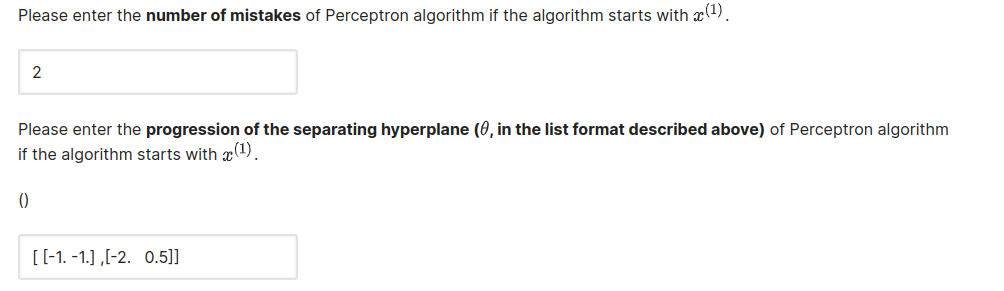

In [ ]:
import numpy as np 
X = np.array([[-1,-1],[1,0],[-1,1.5]])

Y = np.array([1, -1, 1 ])

theta = np.zeros(2)

start = 1
i = start-1
cnt = 0

while not all(Y*(X@theta)>0):
    x,y = X[i], Y[i]
    if y*(theta@x)<=0:
      cnt += 1
      theta += y*x
      print(theta)
    i += 1
    if i >= X.shape[0]:
      i = 0

[-1. -1.]
[-2.   0.5]


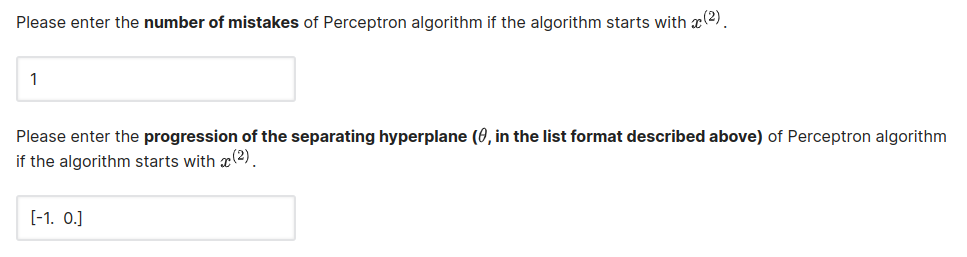

In [ ]:
import numpy as np 
X = np.array([[-1,-1],[1,0],[-1,1.5]])

Y = np.array([1, -1, 1 ])

w = np.zeros(2)
start = 2
i = start-1
cnt = 0

while not all(Y*(X@w)>0):
    x,y = X[i], Y[i]
    if y*(w@x)<=0:
      cnt += 1
      w += y*x
      print(w)
    i += 1
    if i >= X.shape[0]:
      i = 0

[-1.  0.]


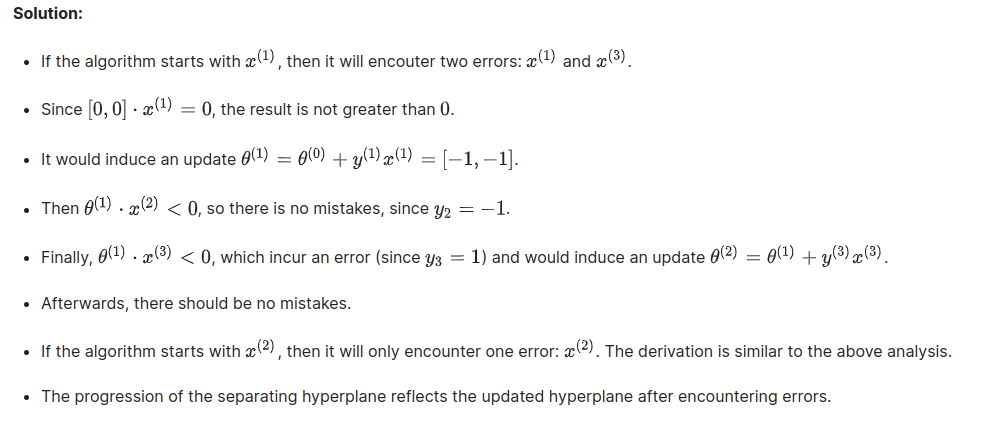

## **1 (b) Factors affecting no. of mistakes made by algo?**

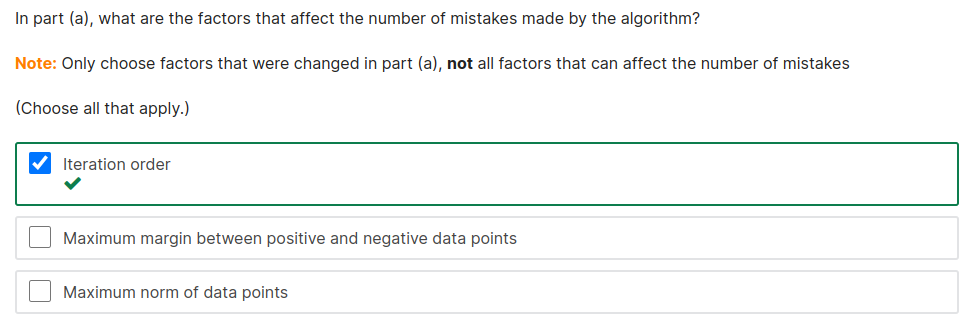

## **1 (c) Number of mistakes of Perceptron alg**

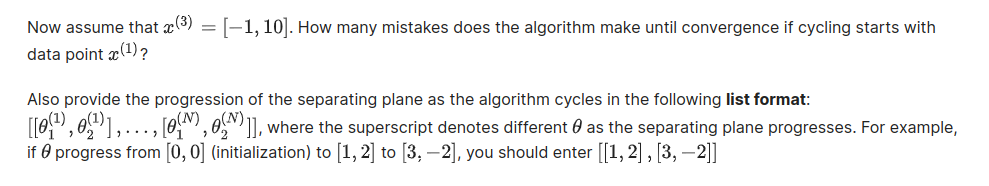

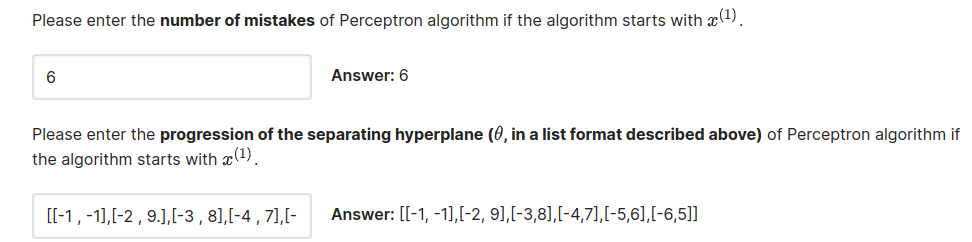

In [ ]:
import numpy as np 
X = np.array([[-1,-1],[1,0],[-1,10]])

Y = np.array([1, -1, 1 ])

w = np.zeros(2)
start = 1
i = start-1
cnt = 0

while not all(Y*(X@w)>0):
    x,y = X[i], Y[i]
    if y*(w@x)<=0:
      cnt += 1
      w += y*x
      print(w)
    i += 1
    if i >= X.shape[0]:
      i = 0

[-1. -1.]
[-2.  9.]
[-3.  8.]
[-4.  7.]
[-5.  6.]
[-6.  5.]


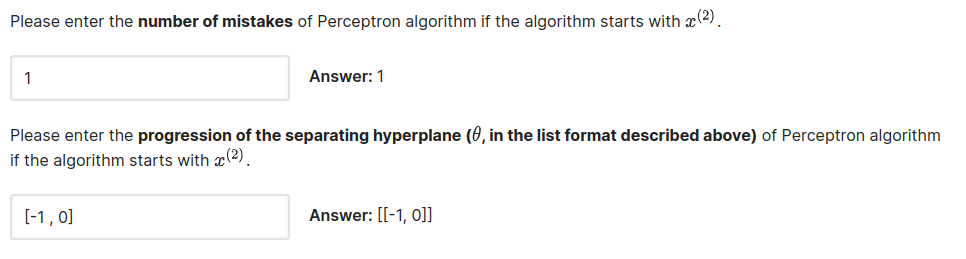

In [ ]:
import numpy as np 
X = np.array([[-1,-1],[1,0],[-1,10]])

Y = np.array([1, -1, 1 ])

w = np.zeros(2)
start = 2
i = start-1
cnt = 0

while not all(Y*(X@w)>0):
    x,y = X[i], Y[i]
    if y*(w@x)<=0:
      cnt += 1
      w += y*x
      print(w)
    i += 1
    if i >= X.shape[0]:
      i = 0

[-1.  0.]


In [ ]:
import numpy as np 
X = np.array([[-1,-1],[1,0],[-1,10]])

Y = np.array([1, -1, 1 ])

w = np.zeros(2)
start = 2
i = start-1
cnt = 0

for T in range(6):
    x,y = X[i], Y[i]
    if y*(w@x)<=0:
      cnt += 1
      w += y*x
      print(w)
    i += 1
    if i >= X.shape[0]:
      i = 0

[-1.  0.]


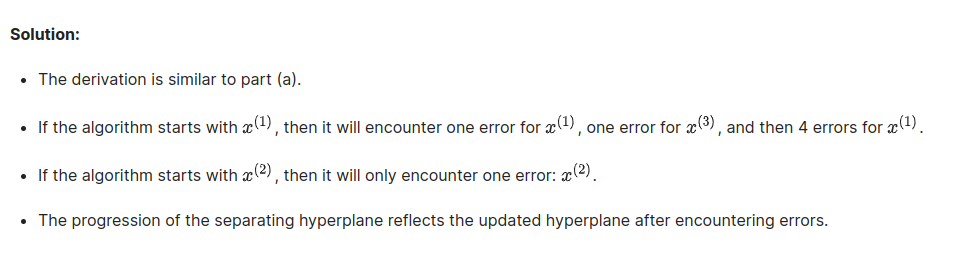

## **1 (d) Fixed iteration order**

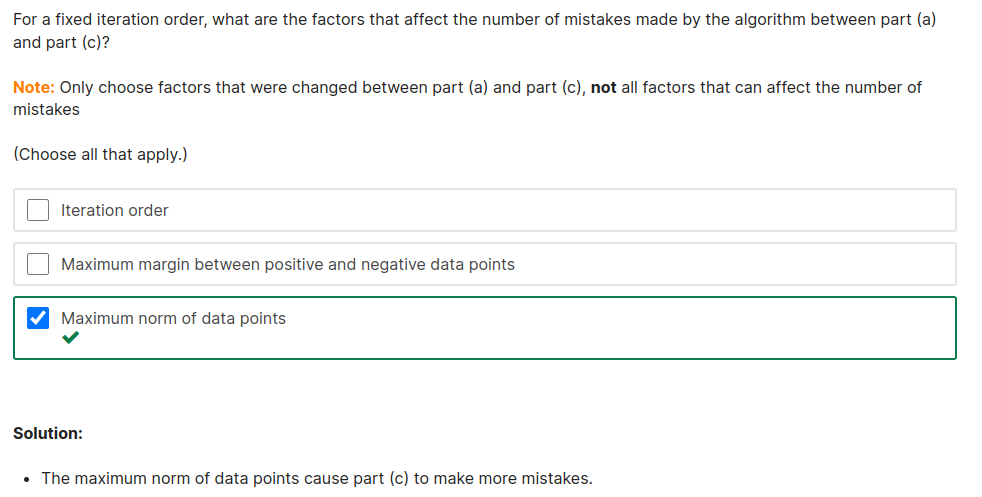

## **1 (e) Perceptron Mistake Bounds**



Novikoff Theorem (1962): https://arxiv.org/pdf/1305.0208.pdf

**Assumptions:**

- There exists an optimal $\theta^* ~$ such that $\frac{y^{(i)}(\theta ^* x^{(i)})}{\| \theta ^* \| } \geq \gamma ∀ i= 1,...,n ~ \text{and some}~ \gamma >0$ (the data is separable by a linear classifier through the origin)
- All training data set examples are bounded by being $\| x^{(i)}\|  \leq R, i=1,\cdots ,n$

**Predicate:**

Then the number of $k$ updates of the perceptron algorithm is bounded by $k<\frac{R²}{\gamma^2}$


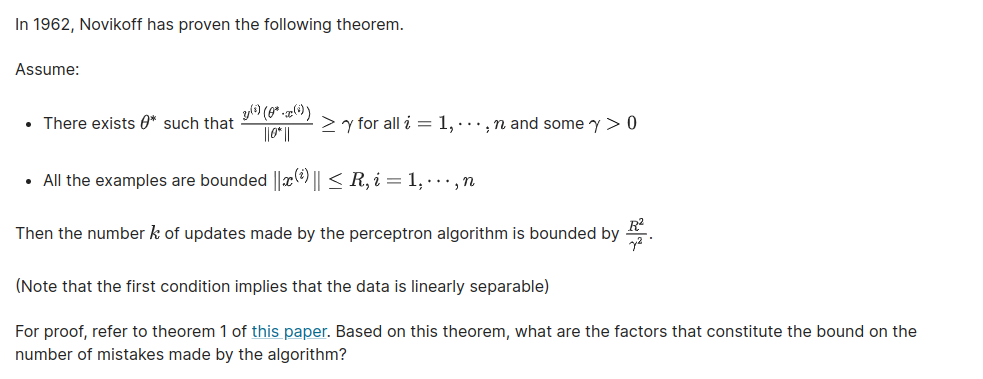

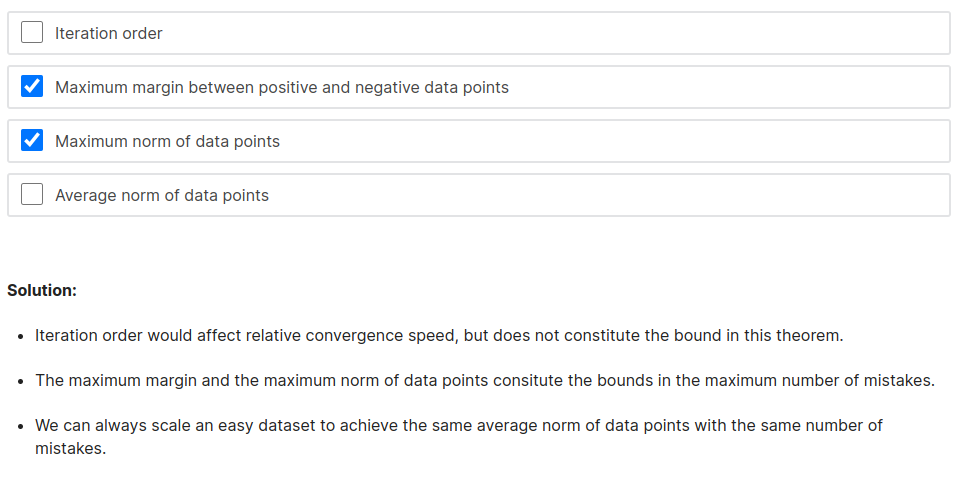

## **1 (f)**


Now we want to establish an adversarial procedure to maximize the number of mistakes the perceptron algorithm makes. What are possible solutions? You should consider a general dataset instead of part (a) and part (c). 

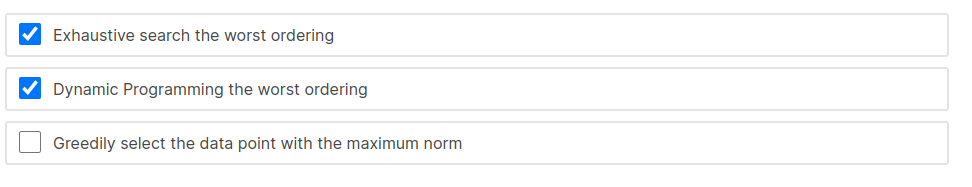

**`Solution:`**

* There are only finitely possible iteration orders, since the algorithm can converge in finite adjustments. As a direct result, exhaustic search can always find the worst ordering.

* Given any prior mistakes made by the algorithm, we know that the maximum number of mistakes should be prior mistakes plus maximum future mistakes. Hence, optimal substructure exist and dynamic programming can be applied.



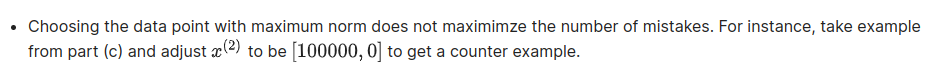

# **2. Perceptron Performance**


## **2. (a) Explore other Initialization choices**


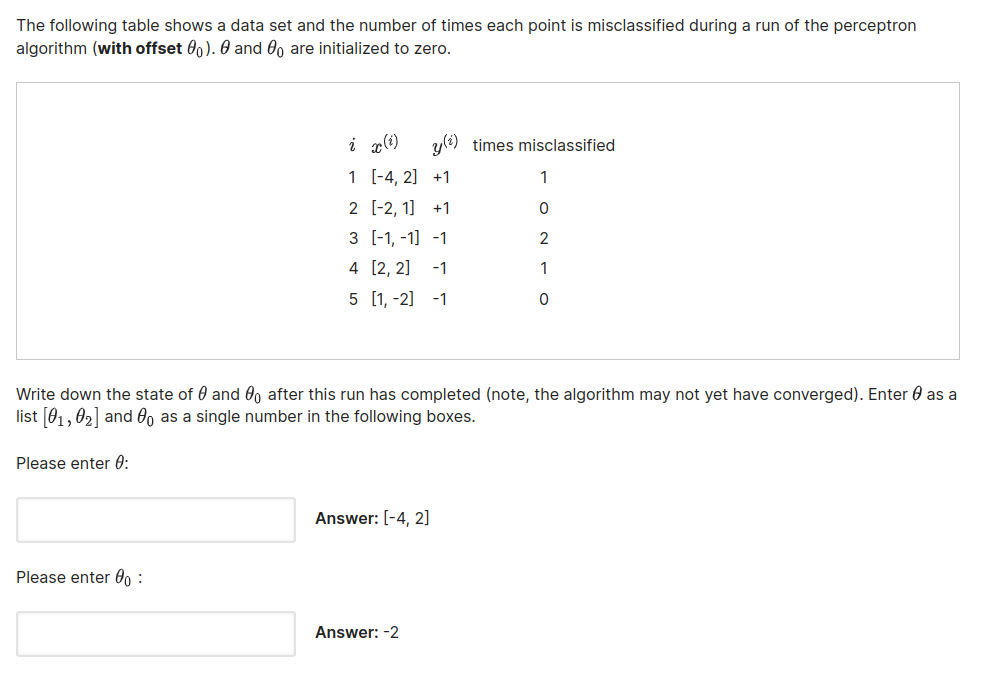

In [ ]:
import numpy as np 
X = np.array([[-4,2],[-2,1],[-1,-1],[2,2],[1,-2]])

Y = np.array([1, 1, -1 , -1 ,-1])

w = np.zeros(2)
w_0 = np.array([0])

start = 1
i = start-1
cnt = 0


# while not all(Y*(X@w)>0):
for T in range(8):
  x,y = X[i], Y[i]
  if y*(w@x+w_0)<=0:
    cnt += 1
    w += y*x
    w_0 += y 
      
    print('theta :', w)
    print('theta_0 :', w_0)

  i += 1
  if i >= X.shape[0]:
    i = 0

theta : [-4.  2.]
theta_0 : [1]
theta : [-3.  3.]
theta_0 : [0]
theta : [-5.  1.]
theta_0 : [-1]
theta : [-4.  2.]
theta_0 : [-2]


## **2. (b)**

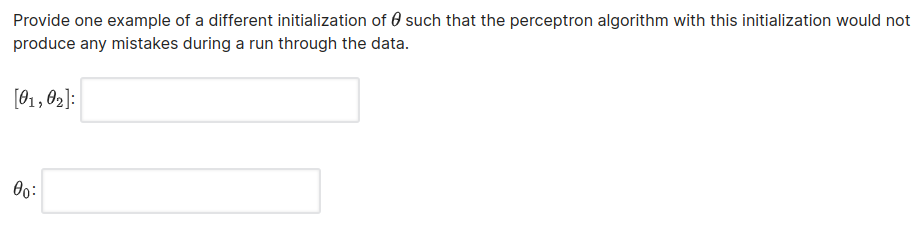

In [ ]:
import numpy as np 
X = np.array([[-4,2],[-2,1],[-1,-1],[2,2],[1,-2]])

Y = np.array([1, 1, -1 , -1 ,-1])

w = np.array([2, 2])
w_0 = np.array([1])

start = 3
i = start-1
cnt = 0

# while not all(Y*(X@w)>0):
for T in range(2):
  x,y = X[i], Y[i]
  if y*(w@x+w_0)<=0:
    cnt += 1
    w += y*x
    w_0 += y    
    print('theta :', w)
    print('theta_0 :', w_0)

  i += 1
  if i >= X.shape[0]:
    i = 0

theta : [0 0]
theta_0 : [0]


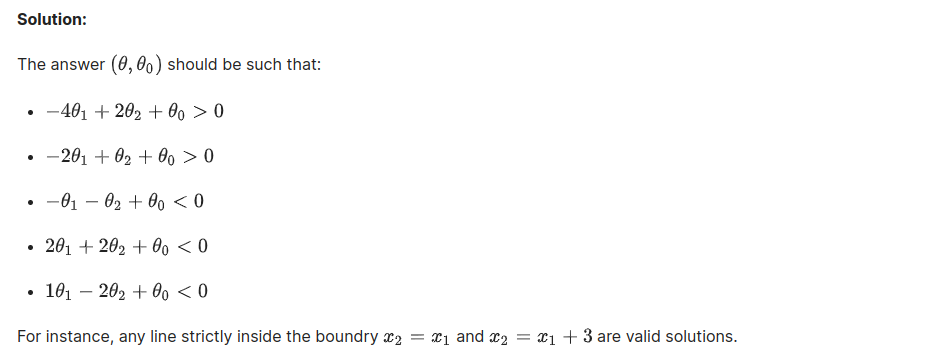

In [ ]:
import numpy as np 

def perceptron_with_offset(X, Y,theta, theta_0, start, T):
  i = start-1
  cnt = 0

  for j in range(T):
    x,y = X[i], Y[i]
    if y*(theta@x + theta_0)<=0:
      cnt += 1
      theta += y*x
      theta_0+=y
      print("theta: ", theta)
      print("theta_not: ", theta_0)  
    i += 1
    if i >= X.shape[0]:
      i = 0
    return 0


def main():
  X = np.array([[-4,2], [-2,1], [-1,-1], [2,2], [1,-2]])

  Y = np.array([1, 1, -1 , -1 ,-1])

  theta =  np.array([2, 2])

  theta_0 = np.array([1])

  start = 3 

  T = 8

  perceptron_with_offset(X,Y,theta,theta_0, start, T)  

if __name__ == "__main__":
    main()


## **2. (c)**


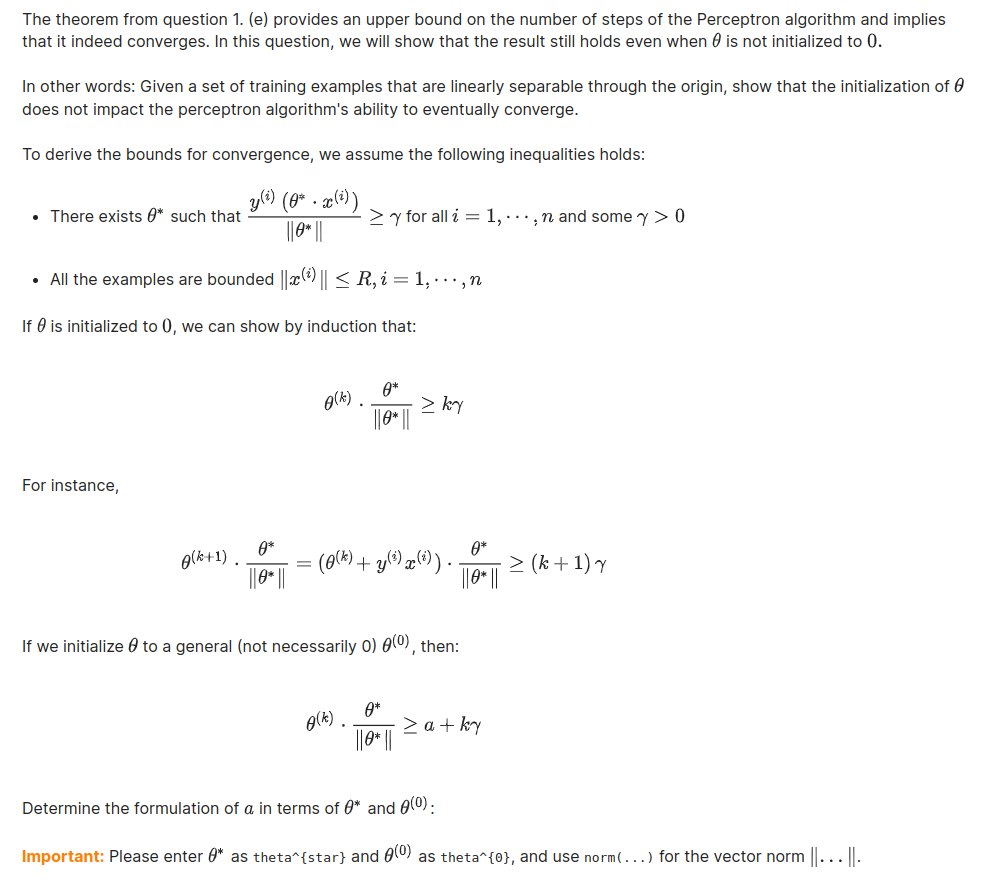

**a =**

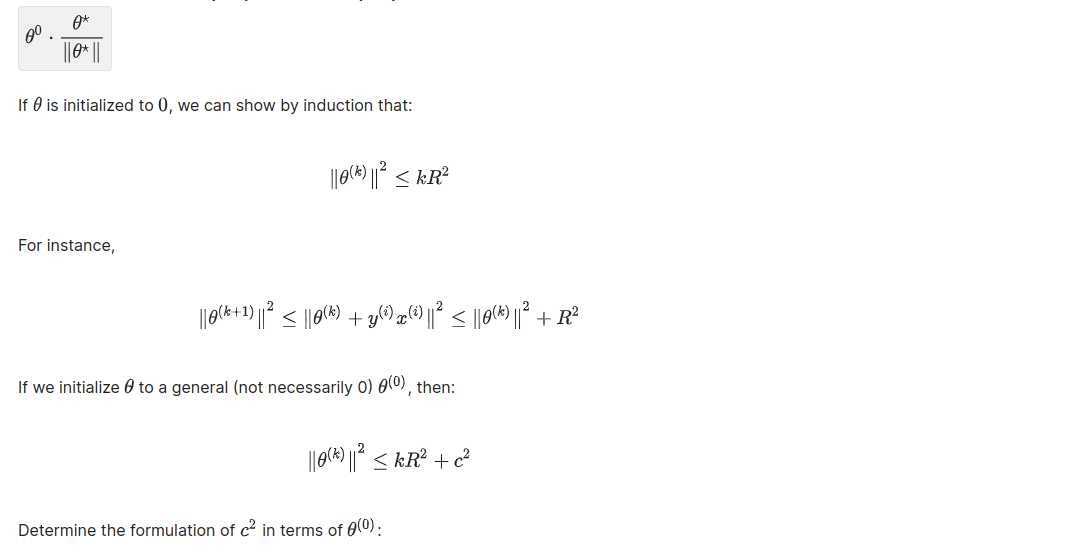

$c^2 =$

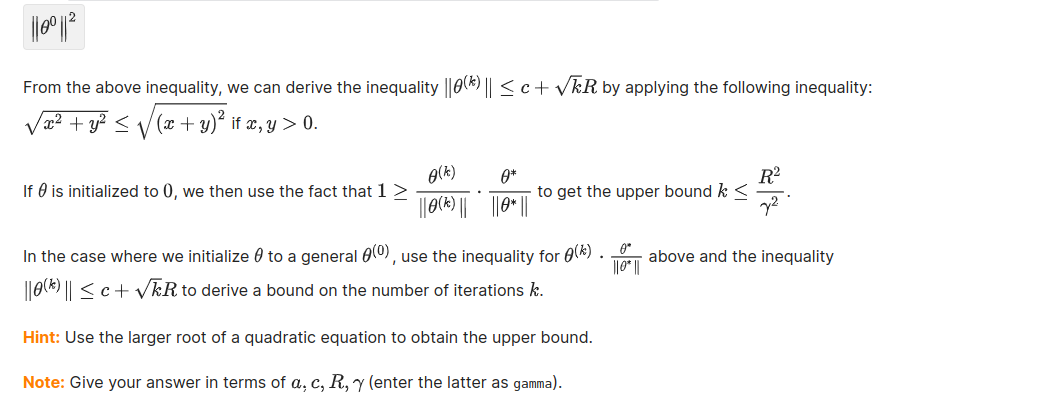

$ k \le \frac{R\cdot \sqrt{R^{2}+4\cdot (c-a)\cdot \gamma}+R^{2}+2\cdot (c-a)\cdot \gamma}{2\cdot \gamma^{2}}$

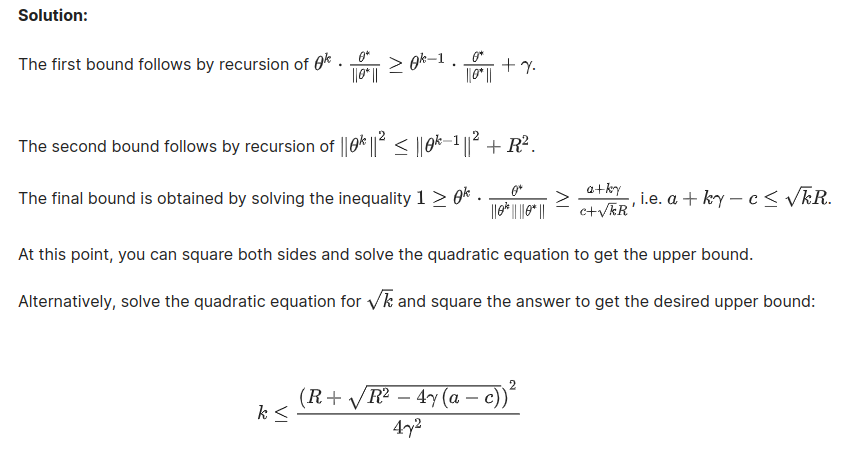

## **2. (d) Perceptron Performance**


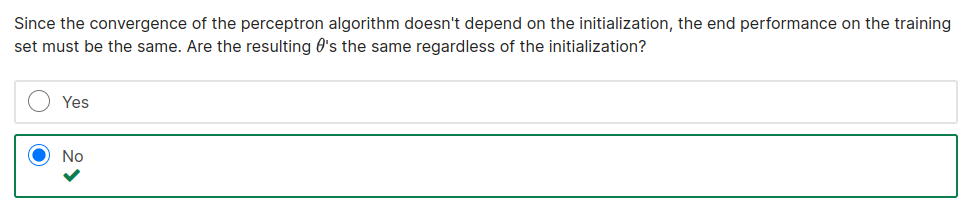

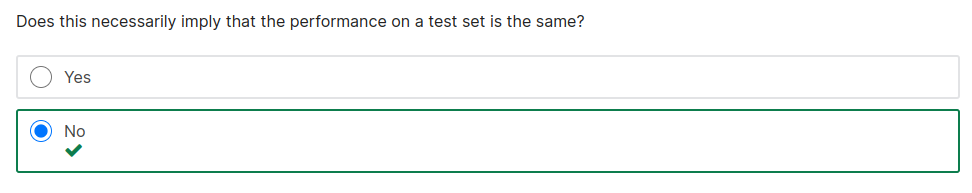

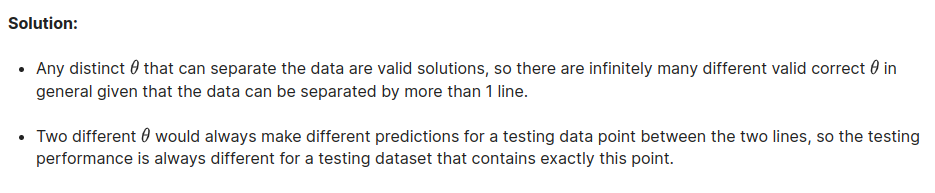

# **3. Decision Boundaries**


## **How to get $\theta$ and $\theta_0$ from a line**


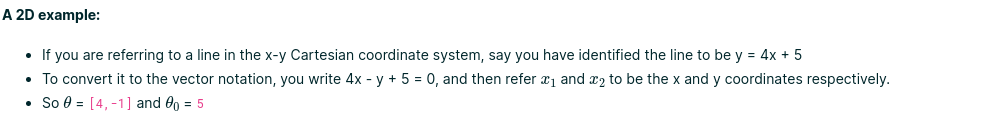

In [ ]:
z = 4x + 5y + 10 plot type in google

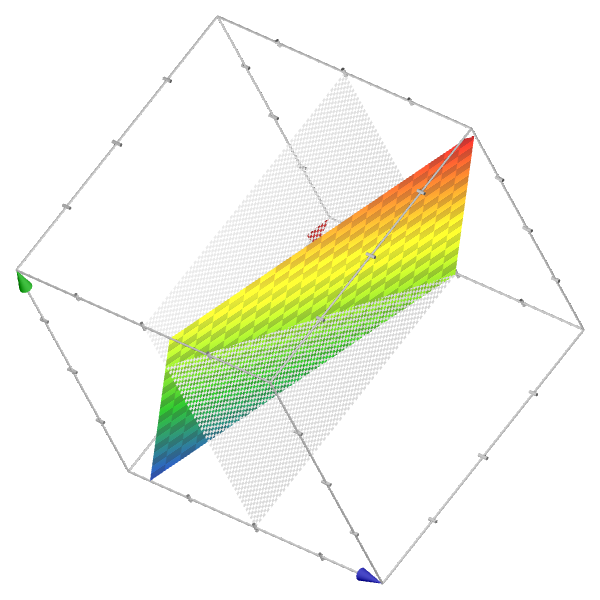

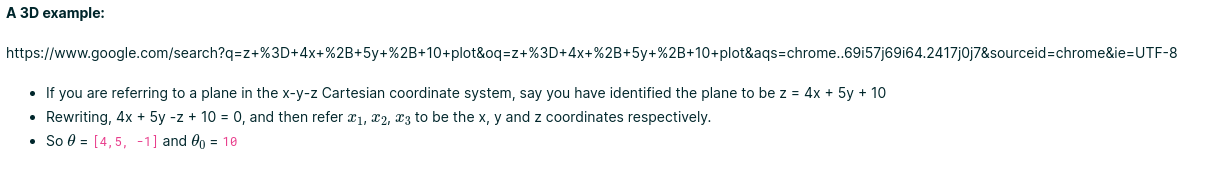

In this problem, we will investigate the **decision boundary of different classifiers**.



https://www.youtube.com/watch?v=ZB3jIH5Oms8&ab_channel=AlanSaberi

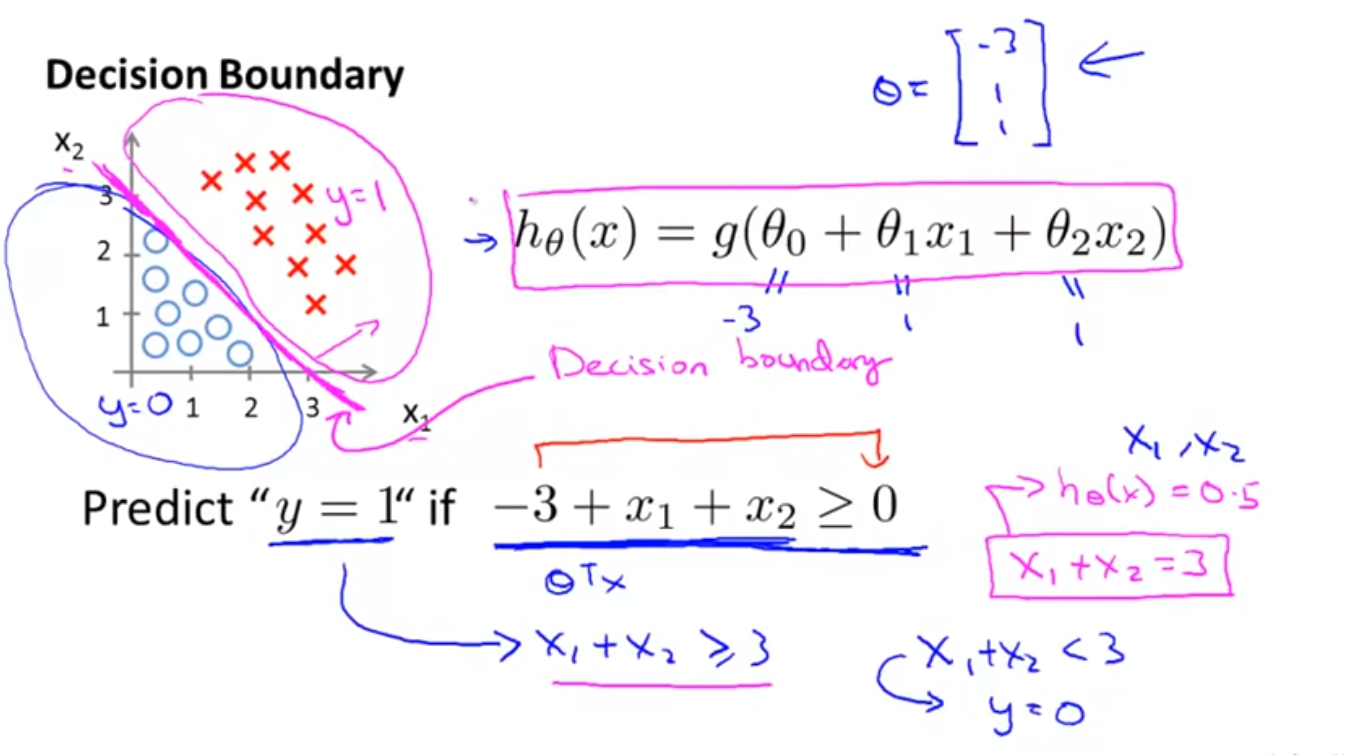

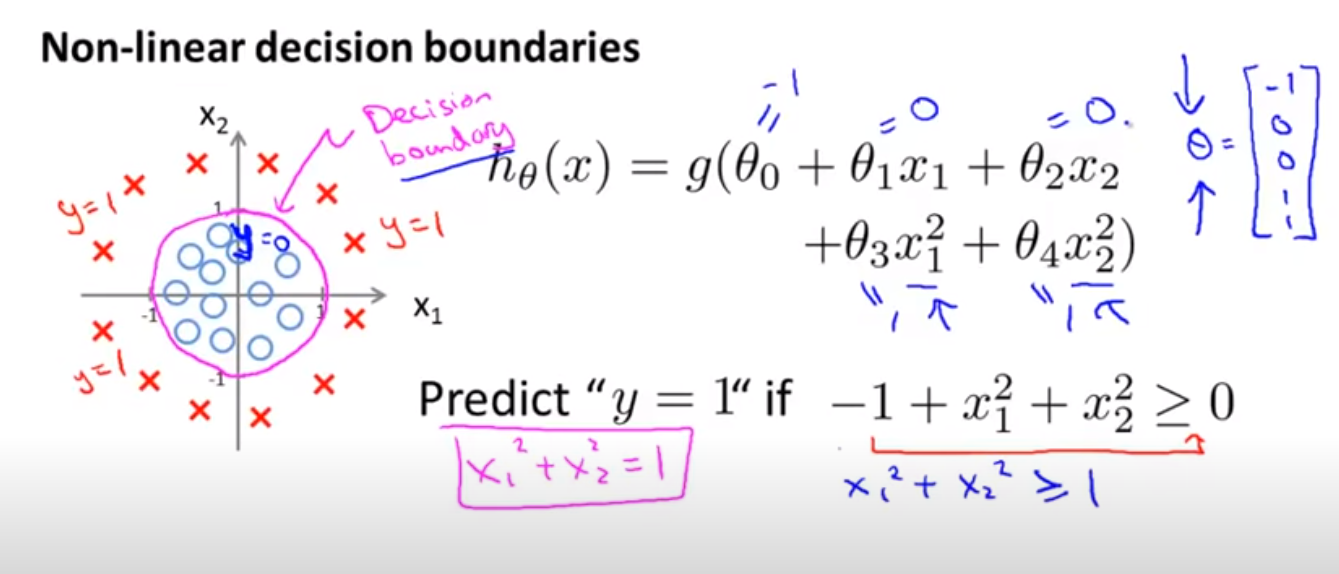

## **3. (a) Learning**

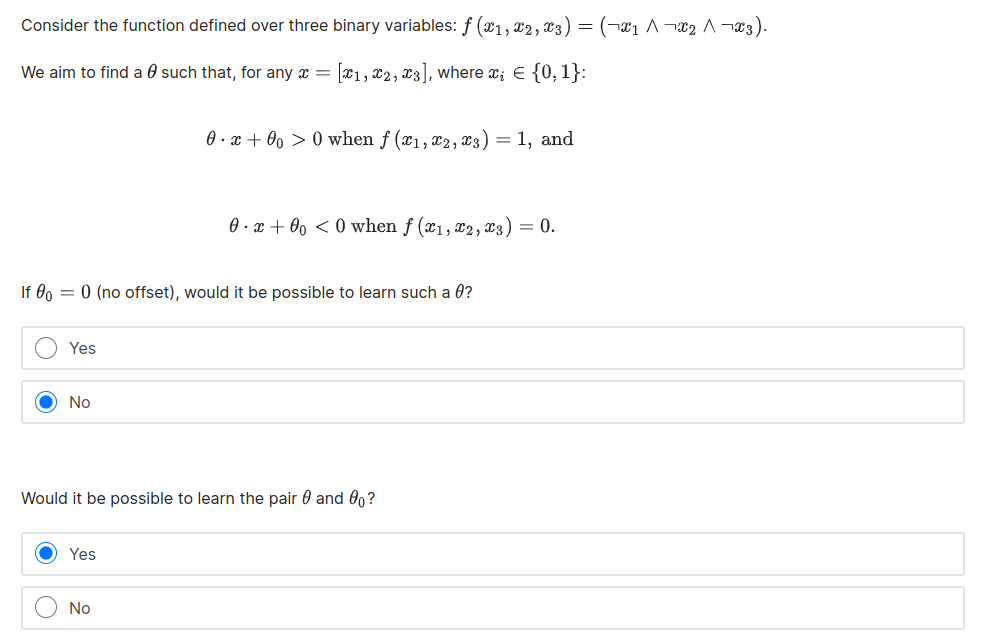

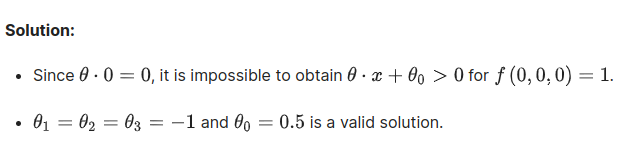

## **3. (b-1)**


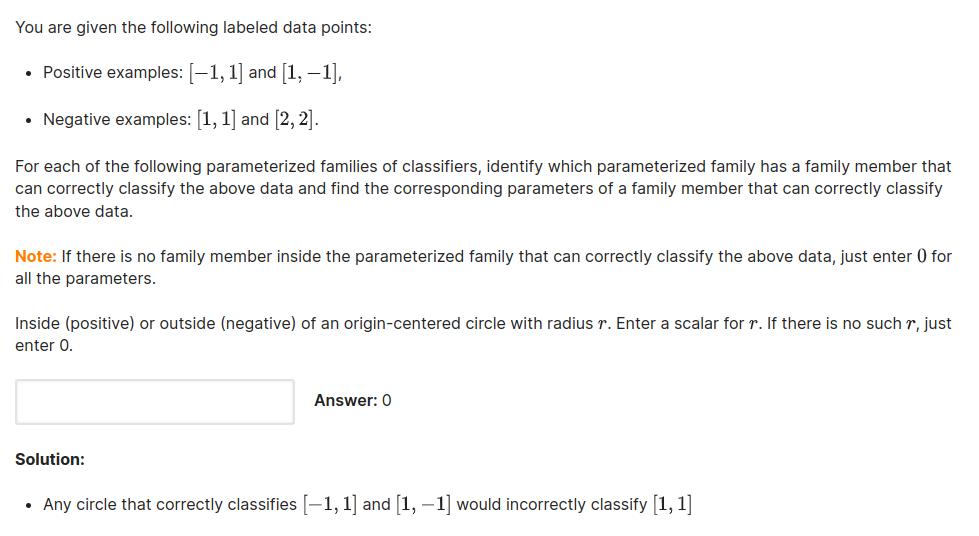

## **3. (b-2)**

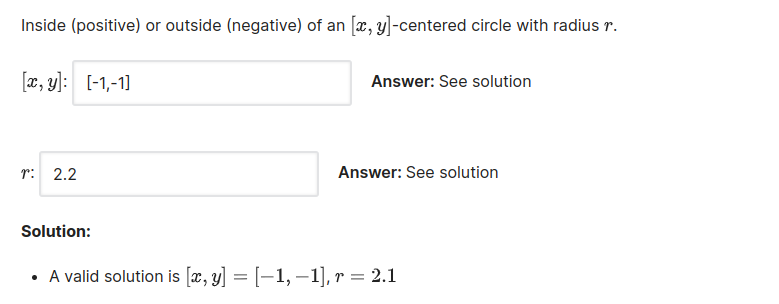

* https://www.geogebra.org/calculator

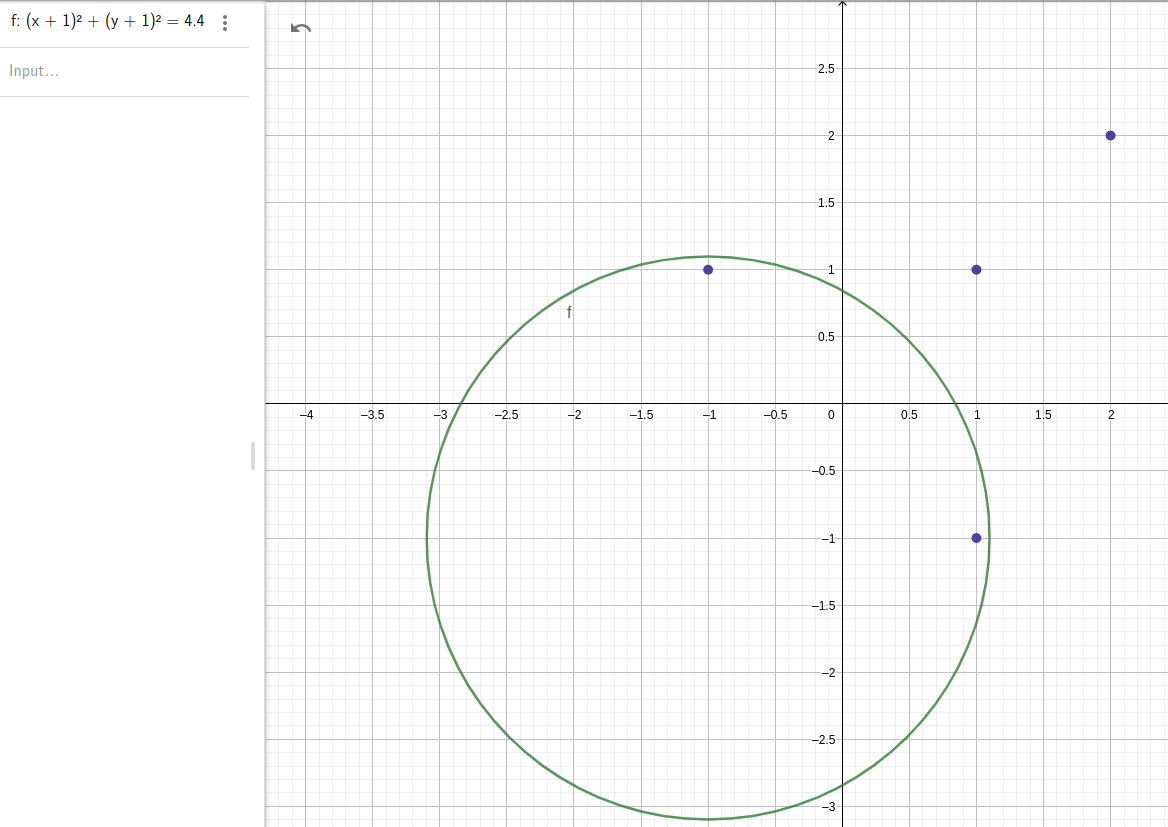

## **3. (b-3) Decision Boundaries via origin**


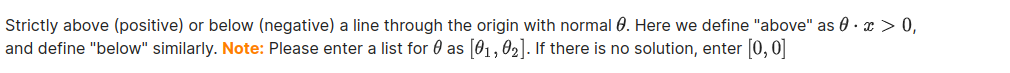

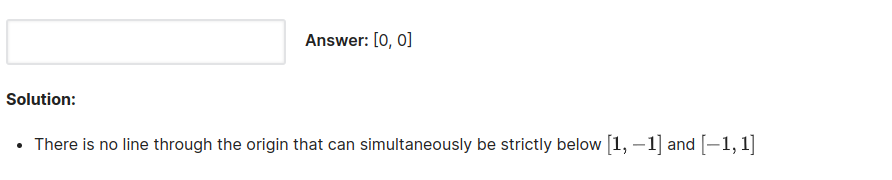

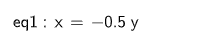

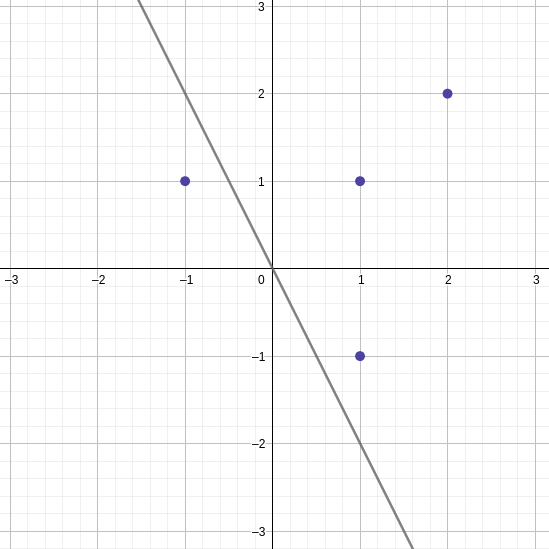

## **3. (b-4) Decision Bound with offset**


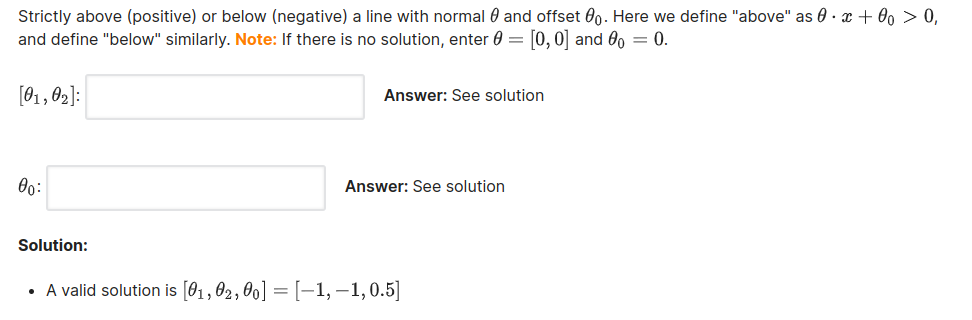

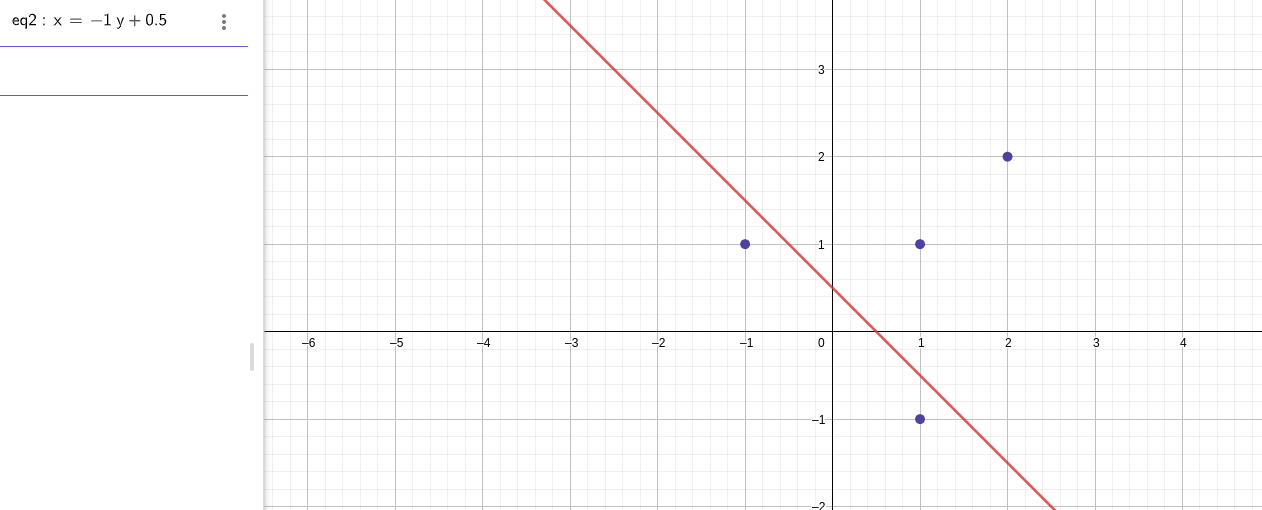

## **3. (b-5) Families of linear classifiers?**


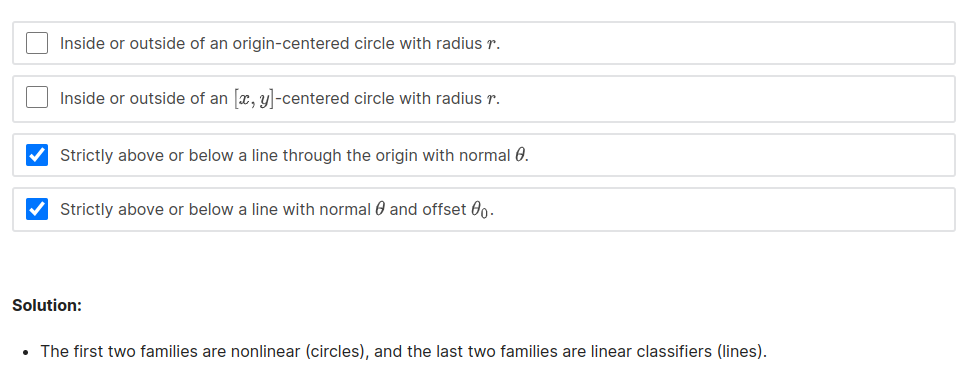

# **4. Linear Support Vector Machines**


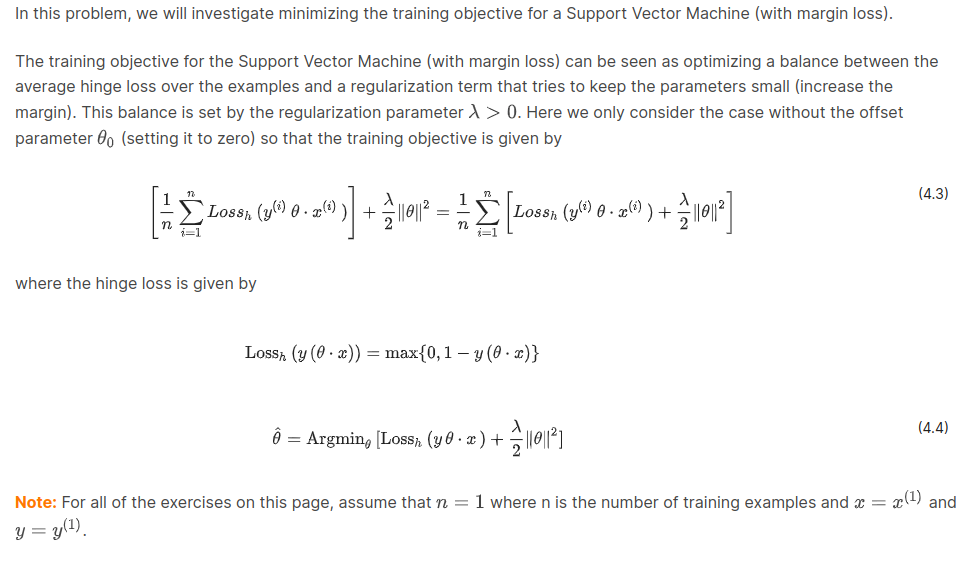

## **Minimizing Loss - Case 1**


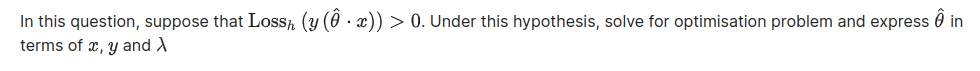

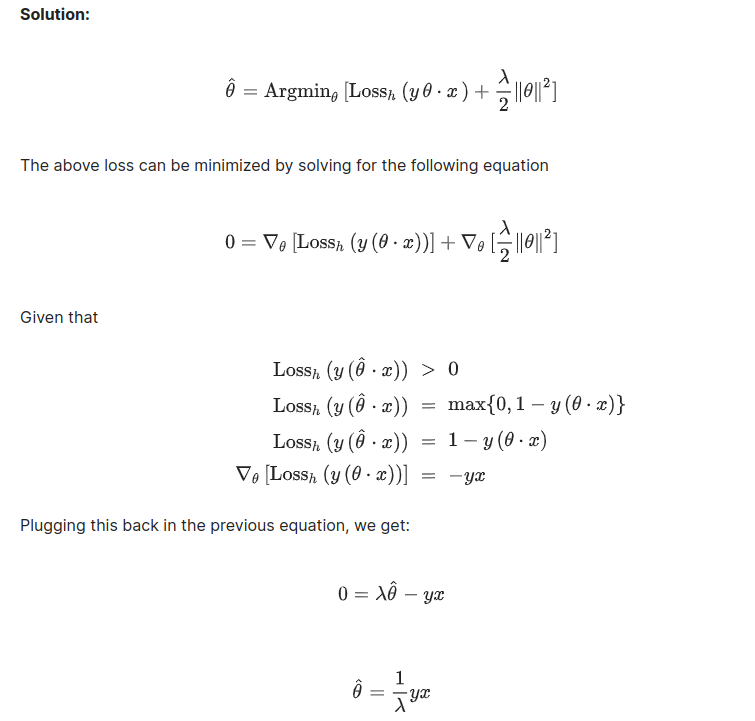

**Different Type**

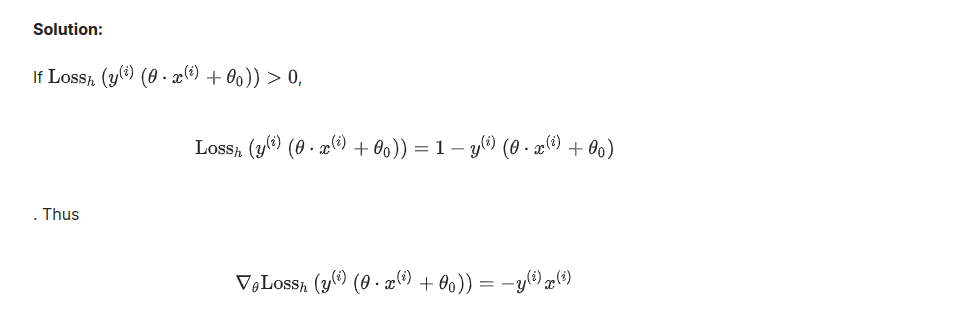

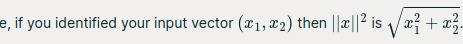

## **Minimizing Loss - Numerical Example (1)**


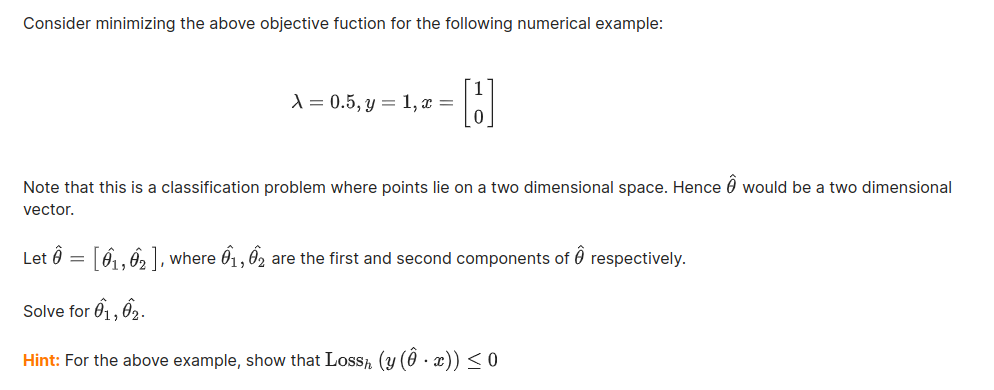

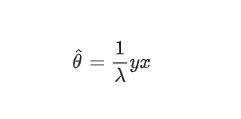

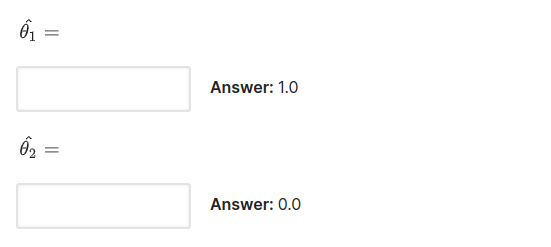

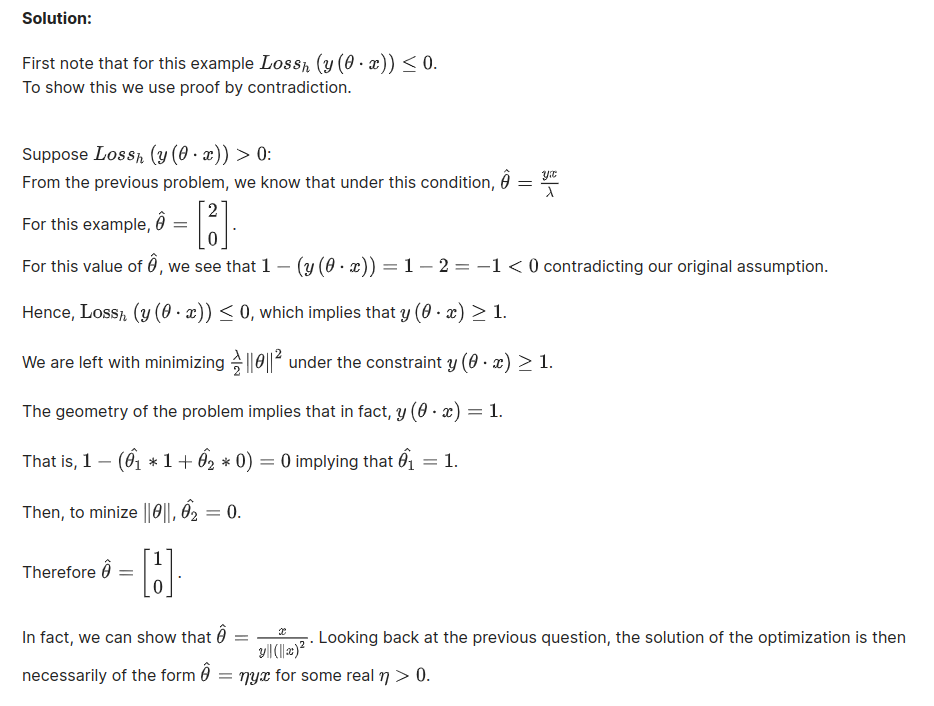

## **Minimizing Loss - Numerical Example (2)**


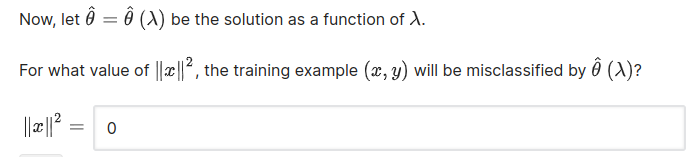

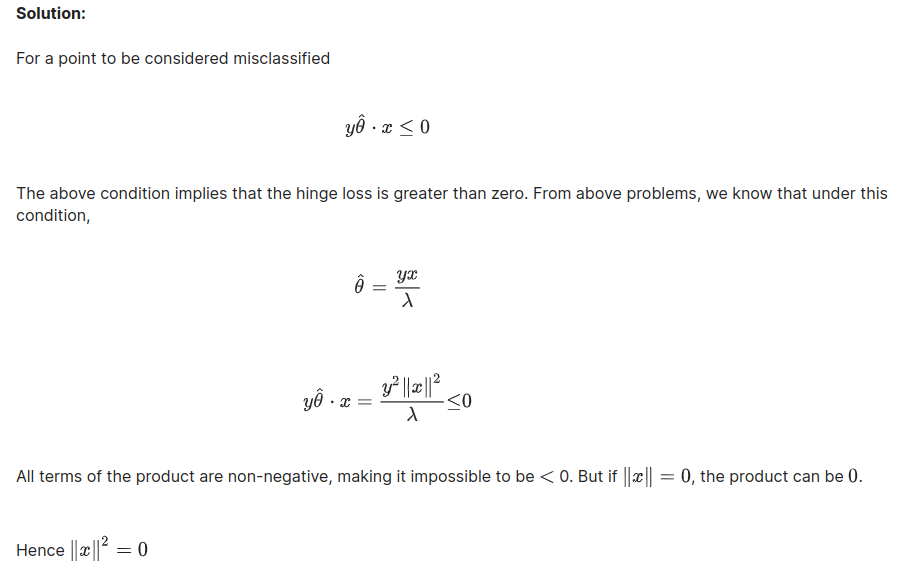

# **5. Passive-aggressive algorithm**


In this problem, we will try to **understand the loss in Passive-Aggressive (PA) Perceptron algorithm.**



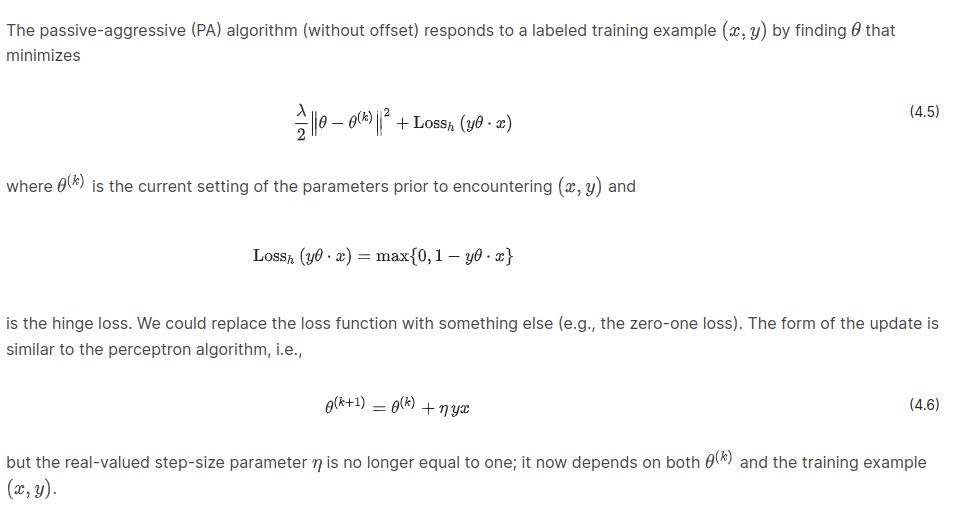

### **5. (a) Update equation**


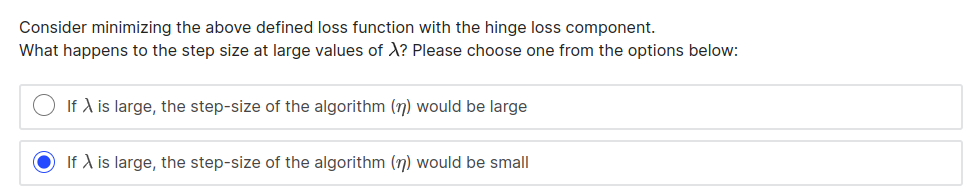

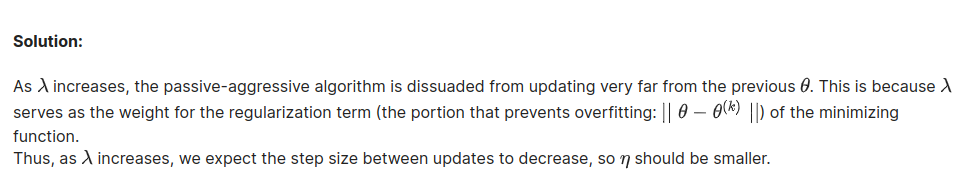

### **5. (b) Calculating the Step size**


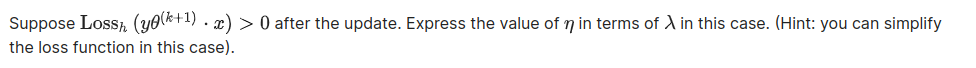

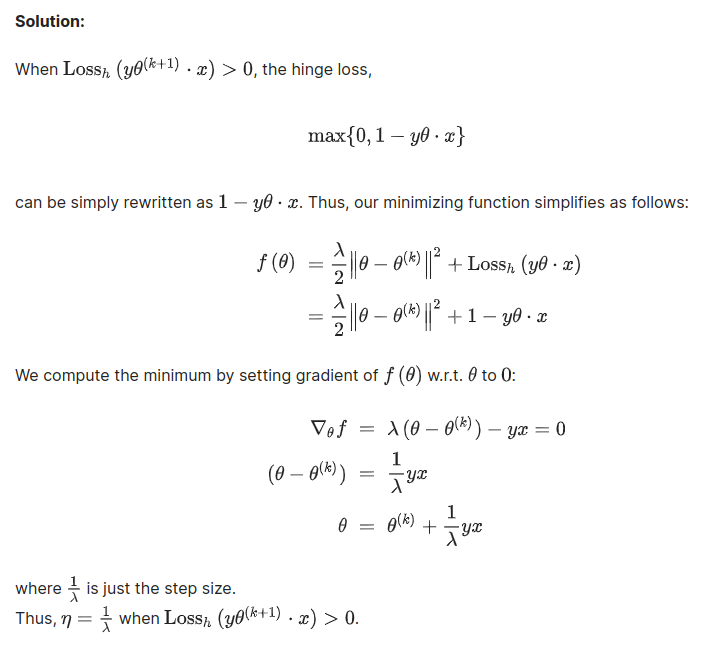

### **5. (c) Loss functions and decision boundaries**


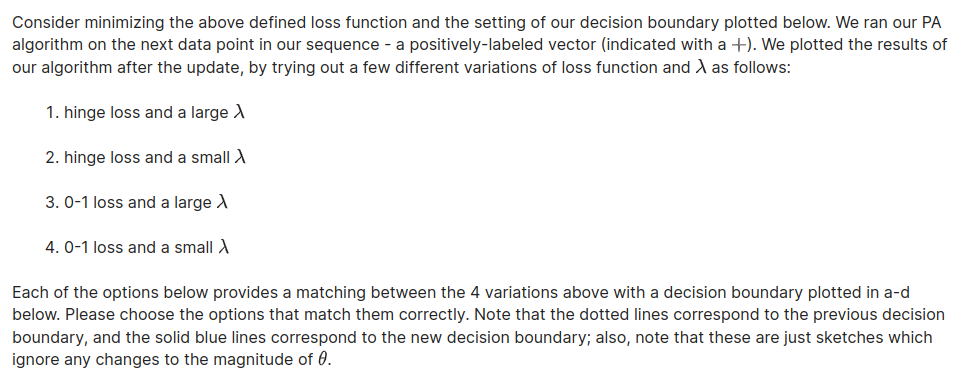

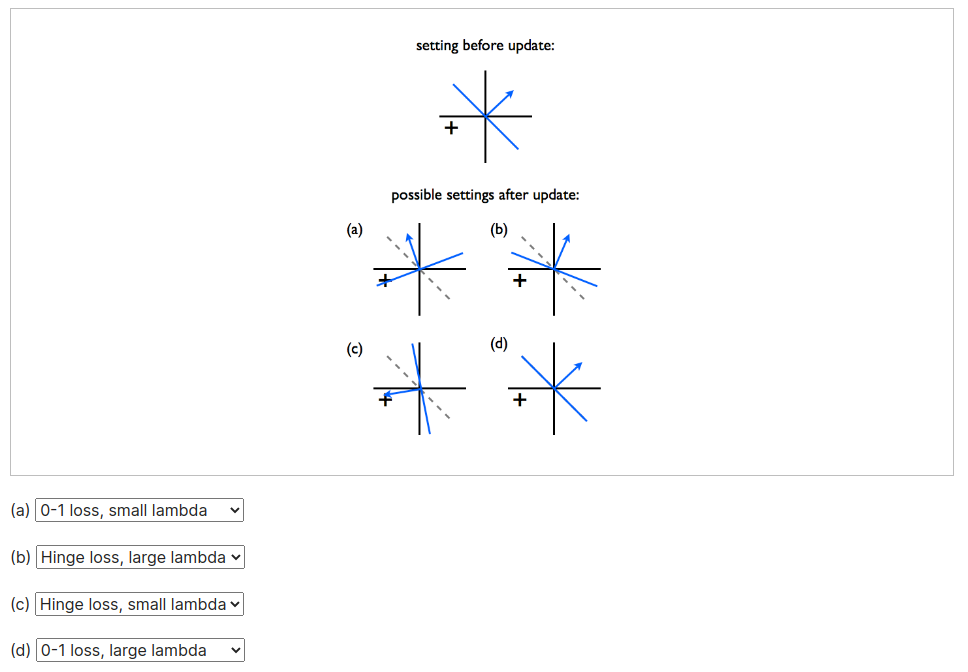

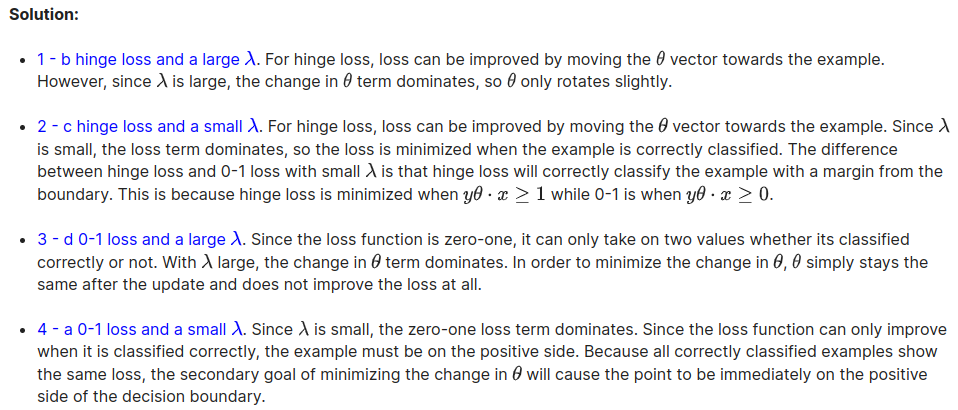

# **6. Perceptron Updates**


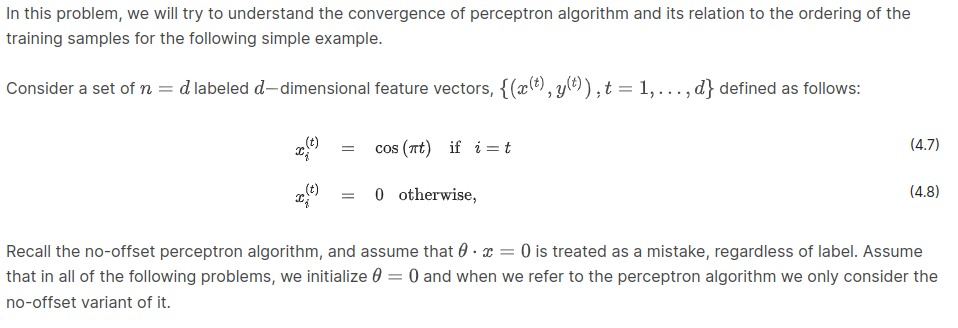

### **Working out Perceptron Algorithm**


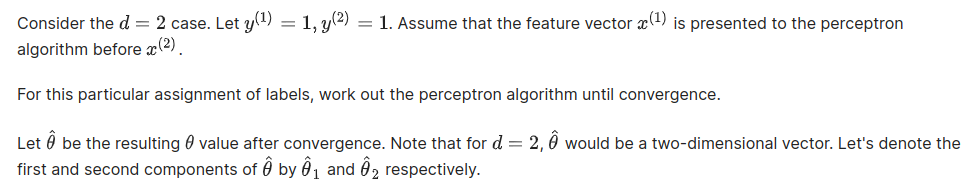

In [ ]:
np.cos(np.array([0, np.pi/2, np.pi]))

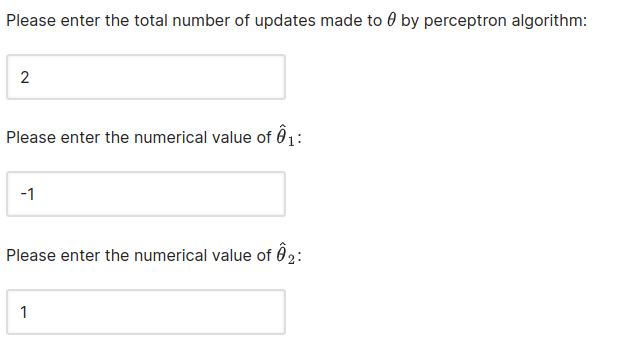

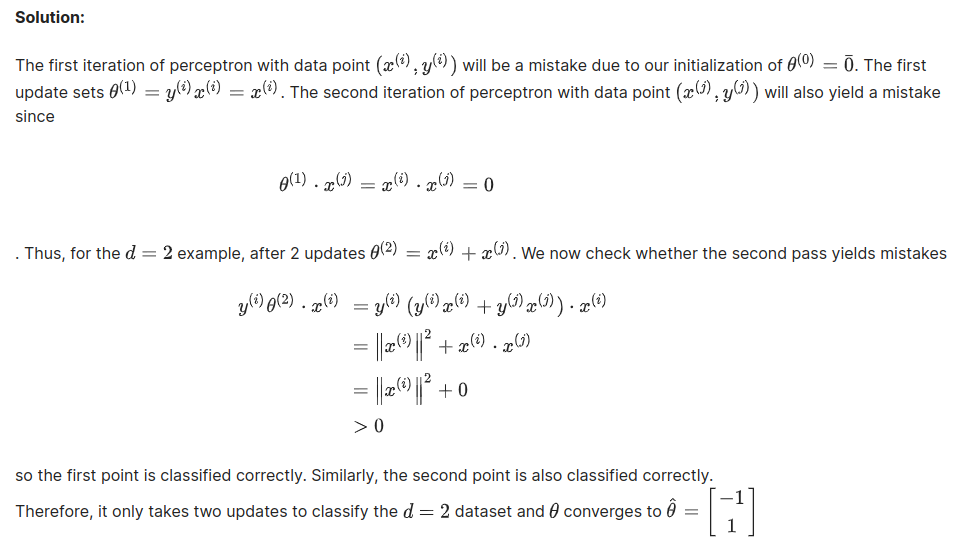

### **General Case - Number of updates**


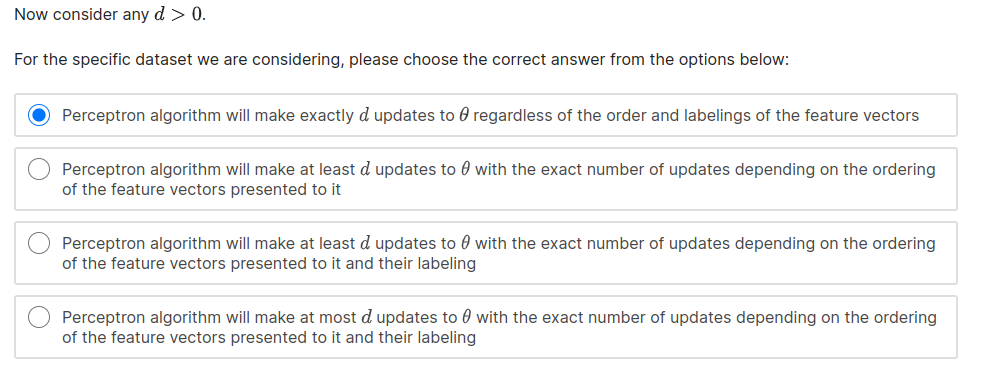

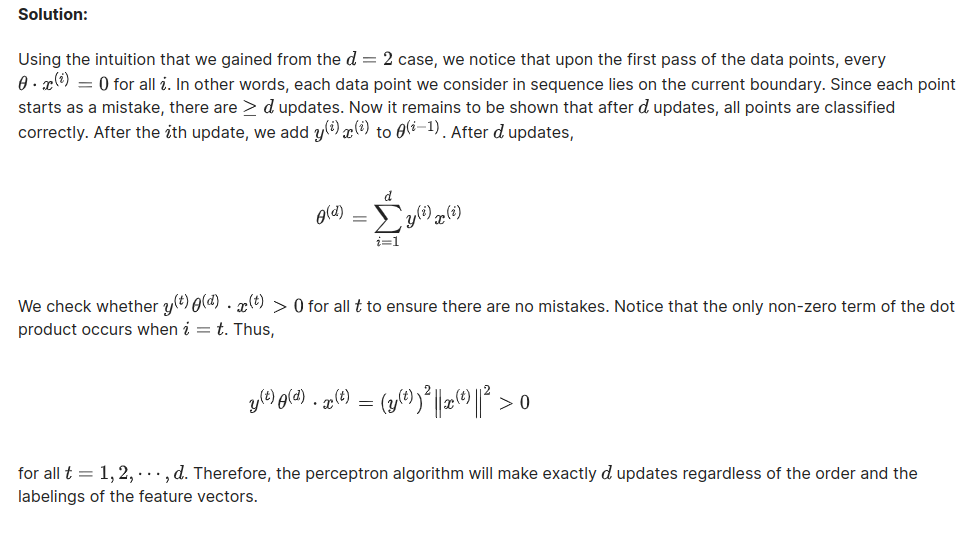

### **Sketching convergence**


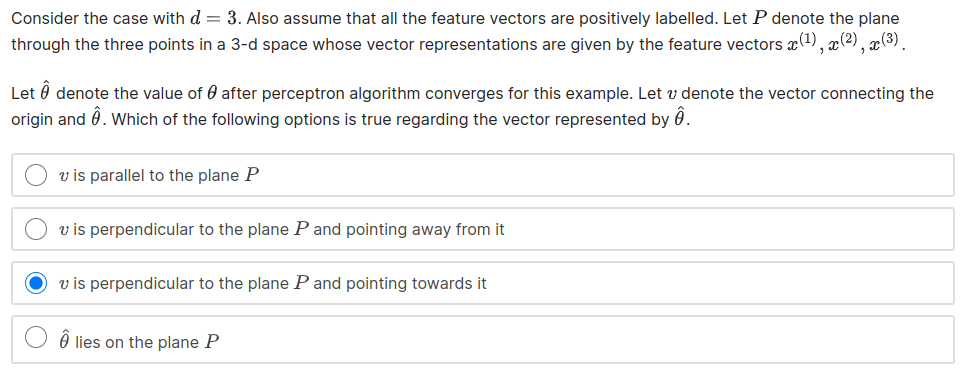

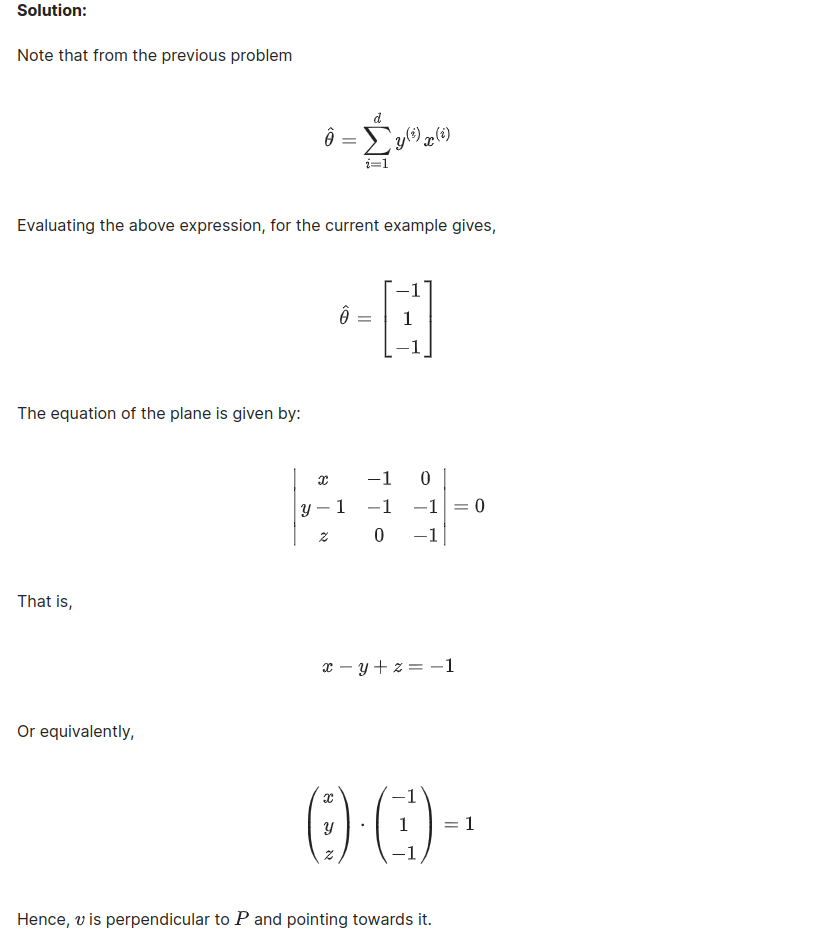